# 🔍 Semantic-Aware Chunking (Qdrant Approach)

Notebook ini difokuskan murni untuk menjalankan **Semantic Chunking** berdasarkan logika dari dokumentasi resmi Qdrant.

**Cara Kerja Algoritma (Qdrant):**
1. Pecah dokumen menjadi kalimat tunggal.
2. Hitung vektor (embedding) untuk setiap kalimat.
3. Hitung *Cosine Similarity* antara kalimat ke-N dan kalimat ke-(N+1).
4. Jika kemiripan makna (*similarity*) turun di bawah *threshold* (misal 0.5), maka potong teks di titik tersebut karena menandakan perpindahan topik.

In [1]:
import sys
from pathlib import Path
import time
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

# Load Model (Bisa diganti ke all-MiniLM-L6-v2 jika ingin lebih cepat)
MODEL_NAME = "sentence-transformers/all-mpnet-base-v2"
model = SentenceTransformer(MODEL_NAME)
TOKEN_LIMIT = model.get_max_seq_length()

def count_tokens(text):
    """
    Menghitung jumlah token menggunakan tokenizer asli HuggingFace (Tanpa LangChain).
    """
    return len(model.tokenizer(text)['input_ids'])

print(f'✅ Model loaded: {MODEL_NAME}')
print(f'📏 Token limit model : {TOKEN_LIMIT}')
print(f'🧪 Test count_tokens("hello world") = {count_tokens("hello world")} tokens')

/home/vinik/Github/vector-search-thesis/venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8912.62it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Model loaded: sentence-transformers/all-mpnet-base-v2
📏 Token limit model : 384
🧪 Test count_tokens("hello world") = 4 tokens


# Import & Load Model

In [2]:
import sys
from pathlib import Path
import time
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

# Load Model (Bisa diganti ke all-MiniLM-L6-v2 jika ingin lebih cepat)
MODEL_NAME = "sentence-transformers/all-mpnet-base-v2"
model = SentenceTransformer(MODEL_NAME)
TOKEN_LIMIT = model.get_max_seq_length()

def count_tokens(text):
    """
    Menghitung jumlah token menggunakan tokenizer asli HuggingFace (Tanpa LangChain).
    """
    return len(model.tokenizer(text)['input_ids'])

print(f'✅ Model loaded: {MODEL_NAME}')
print(f'📏 Token limit model : {TOKEN_LIMIT}')
print(f'🧪 Test count_tokens("hello world") = {count_tokens("hello world")} tokens')

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8869.33it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Model loaded: sentence-transformers/all-mpnet-base-v2
📏 Token limit model : 384
🧪 Test count_tokens("hello world") = 4 tokens


# Load Data

In [7]:
# ─── Sesuaikan path CSV kamu di sini ─────────────────────────────────────────
FILE_COVER  = '../src/assets/dss_trade_agreements_202602201509.csv'
FILE_DETAIL = '../src/assets/dss_trade_agreement_detail_formatted_202602201508.csv'  
DATA_LIMIT  = None  # set angka (misal 500) untuk batasi data pengujian
# ─────────────────────────────────────────────────────────────────────────────

dt_cover  = pd.read_csv(FILE_COVER)
dt_detail = pd.read_csv(FILE_DETAIL)

# Merge & Clean
df = pd.merge(dt_detail, dt_cover, left_on='rta_id', right_on='id', how='inner')
df = df.dropna(subset=['article_text'])
df = df.drop_duplicates(subset=['article_text', 'Agreement'])

if DATA_LIMIT:
    df = df.head(DATA_LIMIT)

# Bangun kolom text_to_vector
def build_text_to_vector(row):
    agreement_name = row['Agreement']
    chapter_name   = row['chapter_name'] if pd.notna(row['chapter_name']) else 'General Provisions'
    article_name   = row['article_name']  if pd.notna(row['article_name'])  else ''
    article_text   = row['article_text']
    return f"{agreement_name} - {chapter_name} - {article_name}: {article_text}"

df['text_to_vector'] = df.apply(build_text_to_vector, axis=1)
df['text_token_count'] = df['text_to_vector'].apply(count_tokens)

print(f'📊 Total Data Siap Diproses: {len(df)} baris')
df[['Agreement','article_name','text_token_count']].head(3)

/tmp/ipykernel_64636/1431687884.py:8: DtypeWarning: Columns (13,14) have mixed types. Specify dtype option on import or set low_memory=False.
  dt_detail = pd.read_csv(FILE_DETAIL)


📊 Total Data Siap Diproses: 80004 baris


,Agreement,article_name,text_token_count
0,Russian Federation - Azerbaijan,Preamble,136
1,Russian Federation - Azerbaijan,NaN,223
2,Russian Federation - Azerbaijan,NaN,129


# Semantic Chunking (Qdrant)

In [8]:
def cosine_similarity(a, b):
    """Fungsi pembantu untuk menghitung Cosine Similarity Numpy"""
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

def semantic_chunking_qdrant(text, model, similarity_threshold=0.5):
    """
    Logika Semantic Chunking persis seperti dokumentasi Qdrant.
    """
    # 1. Pecah teks menjadi kalimat (Menggunakan Regex agar tahan banting untuk RTA)
    raw_sentences = re.split(r'[.;\n]+', text)
    sentences = [s.strip() for s in raw_sentences if len(s.strip()) > 5]

    # Jika dokumen hanya 1 kalimat, kembalikan apa adanya
    if len(sentences) <= 1:
        return [text]

    # 2. Embed seluruh kalimat untuk mengecek maknanya
    embeddings = model.encode(sentences)
    
    chunks = []
    current_chunk = [sentences[0]]

    # 3. Looping: Bandingkan kalimat berurutan
    for i in range(1, len(sentences)):
        sim = cosine_similarity(embeddings[i-1], embeddings[i])
        
        # 4. Jika similarity drop (berbeda topik), potong di sini
        if sim < similarity_threshold:
            chunks.append('. '.join(current_chunk))
            current_chunk = [sentences[i]]
        # Jika masih mirip, gabungkan ke chunk yang sama
        else:
            current_chunk.append(sentences[i])

    # Masukkan sisa kalimat terakhir
    if current_chunk:
        chunks.append('. '.join(current_chunk))

    return chunks

# --- Test Fungsi ---
sample_text = df['text_to_vector'].iloc[50] # Ambil 1 sampel
test_chunks = semantic_chunking_qdrant(sample_text, model, similarity_threshold=0.5)

print(f"✅ Fungsi Qdrant berjalan sukses!")
print(f"📄 Teks asli dipecah menjadi {len(test_chunks)} chunk koheren.")

✅ Fungsi Qdrant berjalan sukses!
📄 Teks asli dipecah menjadi 1 chunk koheren.


# Eksekusi ke Seluruh Data

In [9]:
results = []
start_time = time.time()

# Looping ke seluruh data di dataframe
for idx, row in df.iterrows():
    full_text = row['text_to_vector'] 
    
    # Eksekusi fungsi Qdrant
    chunks = semantic_chunking_qdrant(full_text, model, similarity_threshold=0.5)
    
    was_chunked = len(chunks) > 1

    for chunk_idx, chunk in enumerate(chunks):
        chunk_tokens = count_tokens(chunk)
        results.append({
            'row_index'      : idx,
            'Agreement'      : row['Agreement'],
            'article_name'   : row['article_name'] if pd.notna(row['article_name']) else '',
            'was_chunked'    : was_chunked,
            'chunk_index'    : chunk_idx,
            'total_chunks'   : len(chunks),
            'chunk_tokens'   : chunk_tokens,
            'exceeds_limit'  : chunk_tokens > TOKEN_LIMIT,
            'chunk_text'     : chunk,
        })

end_time = time.time()
result_df = pd.DataFrame(results)

print(f'✅ Proses Selesai dalam {(end_time - start_time)/60:.2f} menit.')
print(f'📦 Total chunks dihasilkan: {len(result_df)}')

✅ Proses Selesai dalam 8.46 menit.
📦 Total chunks dihasilkan: 87116


# Ringkasan & Statistik Akhir

📋 RINGKASAN SEMANTIC CHUNKING (QDRANT)
Total dokumen awal     : 80004
Dokumen yang di-chunk  : 6041 (7.6%)
Total chunks akhir     : 87116
Rata-rata token/chunk  : 194.9
---------------------------------------------
✅ Chunks aman (≤384 tok) : 76978 (88.4%)
⚠️  Chunks > 384 token   : 10138


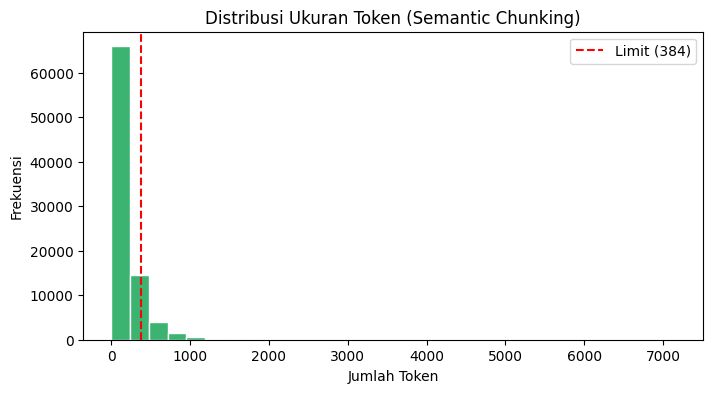

In [10]:
total_docs     = result_df['row_index'].nunique()
total_chunks   = len(result_df)
chunked_docs   = result_df[result_df['was_chunked']]['row_index'].nunique()
safe_chunks    = result_df[~result_df['exceeds_limit']]
over_chunks    = result_df[result_df['exceeds_limit']]

print('=' * 45)
print('📋 RINGKASAN SEMANTIC CHUNKING (QDRANT)')
print('=' * 45)
print(f'Total dokumen awal     : {total_docs}')
print(f'Dokumen yang di-chunk  : {chunked_docs} ({(chunked_docs/total_docs)*100:.1f}%)')
print(f'Total chunks akhir     : {total_chunks}')
print(f'Rata-rata token/chunk  : {result_df["chunk_tokens"].mean():.1f}')
print('-' * 45)
print(f'✅ Chunks aman (≤{TOKEN_LIMIT} tok) : {len(safe_chunks)} ({(len(safe_chunks)/total_chunks)*100:.1f}%)')
print(f'⚠️  Chunks > {TOKEN_LIMIT} token   : {len(over_chunks)}')
print('=' * 45)

# Visualisasi sederhana
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(result_df['chunk_tokens'], bins=30, color='mediumseagreen', edgecolor='white')
ax.axvline(TOKEN_LIMIT, color='red', linestyle='--', label=f'Limit ({TOKEN_LIMIT})')
ax.set_title('Distribusi Ukuran Token (Semantic Chunking)')
ax.set_xlabel('Jumlah Token')
ax.set_ylabel('Frekuensi')
ax.legend()
plt.show()